# Nicheformer Benchmarking

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 04.12.2024
- Date of Last Modification: 06.04.2026 (by Sebastian Birk; sb75@sanger.ac.uk)

- Run this notebook in the nicheformer uv environment, installable from ```../../envs/nicheformer.sh```.
- Clone Nicheformer from GitHub into ```<root>/analysis/benchmarking```: ```git clone https://github.com/theislab/nicheformer```.
- Download the pretrained model weights from https://data.mendeley.com/preview/87gm9hrgm8?a=d95a6dde-e054-4245-a7eb-0522d6ea7dff as described at https://github.com/theislab/nicheformer/blob/main/README.md and put them into the ```./nicheformer/data``` directory.
- For zero shot inference, this notebooks follows the notebook from https://github.com/theislab/nicheformer/blob/main/notebooks/experiments/get_embeddings.ipynb

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")
sys.path.append("../benchmarking/nicheformer/src")

In [3]:
import os
import warnings
from tqdm import tqdm
from typing import Optional, Dict, Any

import anndata as ad
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pybiomart
import pytorch_lightning as pl
import scanpy as sc
import sklearn.metrics as skm
import torch
from torch.utils.data import DataLoader
from pyensembl import EnsemblRelease
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from scib_metrics import ilisi_knn
from scib_metrics.nearest_neighbors import pynndescent
from scipy.spatial.distance import cdist
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from nicheformer.data import NicheformerDataset
from nicheformer.models import Nicheformer

from analysis_utils import *

### 1.2 Configure Paths

In [4]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/stjepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'
nicheformer_folder_path = '/nfs/team361/sb75/stjepa-reproducibility/analysis/mouse_benchmarking/nicheformer'

BASE_PATH = f'{nicheformer_folder_path}/data/model_means'

### 1.3 Define Config

In [49]:
method = 'nicheformer'

# General params
dataset_name = 'mmb0-1b_smb1-1b_1p'
batches = ['harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes',
           'harmonised_starmap_plus_mouse_cns_batch15_shared_genes']
niche_key = 'tissue_region'
label_keys = [niche_key]
species = 'mouse'
n_neighs = 10
spot_sizes = {'MERFISH': 20,
              'STARmap PLUS': 100}
batch_key = 'batch'
n_pcs = None

# Nicheformer params
config = {
    'data_path': f'{artifacts_folder_path}/nicheformer/{dataset_name}.h5ad',
    'technology_mean_path': f"{BASE_PATH}/merfish_mean_script.npy", #'path/to/technology_mean.npy',  # Path to technology mean file
    'checkpoint_path': f'{nicheformer_folder_path}/data/nicheformer.ckpt',  # Path to model checkpoint
    'output_path': f'{benchmarking_artifacts_folder_path}/nicheformer/{dataset_name}_embedded.h5ad',  # Where to save the result, it is a new h5ad
    'output_dir': '.',  # Directory for any intermediate outputs
    'batch_size': 32,
    'max_seq_len': 1500, 
    'aux_tokens': 30, 
    'chunk_size': 1000, # to prevent OOM
    'num_workers': 4,
    'precision': 32,
    'embedding_layer': -1,  # Which layer to extract embeddings from (-1 for last layer)
    'embedding_name': 'embeddings'  # Name suffix for the embedding key in adata.obsm
}
emb_key = f"X_niche_{config.get('embedding_name', 'embeddings')}"

# Cluster params
latent_leiden_resolution = 1.55

### 1.4 Run Notebook Setup

In [6]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [7]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [8]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [9]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [10]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/{method}', exist_ok=True)

In [11]:
# Set random seed for reproducibility
pl.seed_everything(42)

Seed set to 42


42

### 1.5 Define Functions

In [12]:
def make_large_cmap(n):
    base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"
    return [mcolors.to_hex(base(i)) for i in range(n)]

In [13]:
def mmd_comparable(adata, emb_key, batch_key, n_sub=2000, n_sigma=1000):
    # Normalize to zero mean, unit variance
    X = StandardScaler().fit_transform(adata.obsm[emb_key])
    
    # Compute sigma on normalized data
    idx = np.random.choice(len(X), min(n_sigma, len(X)), replace=False)
    sub = X[idx]
    dists = np.linalg.norm(sub[:, None] - sub[None, :], axis=2)
    sigma = np.median(dists[dists > 0])
    
    # Split by batch
    batches = adata.obs[batch_key].unique()
    mask0 = adata.obs[batch_key] == batches[0]
    mask1 = adata.obs[batch_key] == batches[1]
    b0, b1 = X[mask0], X[mask1]
    
    idx0 = np.random.choice(len(b0), min(n_sub, len(b0)), replace=False)
    idx1 = np.random.choice(len(b1), min(n_sub, len(b1)), replace=False)
    
    def rbf(A, B):
        d = np.linalg.norm(A[:, None] - B[None, :], axis=2)
        return np.exp(-d**2 / (2 * sigma**2))
    
    b0s, b1s = b0[idx0], b1[idx1]
    return rbf(b0s, b0s).mean() + rbf(b1s, b1s).mean() - 2 * rbf(b0s, b1s).mean()

In [14]:
def get_mouse_to_human_orthologs():
    """Fetch mouse→human ortholog mapping from Ensembl BioMart."""
    dataset = pybiomart.Dataset(
        name='mmusculus_gene_ensembl',
        host='http://www.ensembl.org'
    )
    orthologs = dataset.query(
        attributes=[
            'ensembl_gene_id',          # mouse Ensembl ID
            'external_gene_name',        # mouse gene symbol
            'hsapiens_homolog_ensembl_gene',  # human Ensembl ID
            'hsapiens_homolog_orthology_type' # orthology type
        ]
    )
    orthologs.columns = ['mouse_ensembl', 'mouse_symbol', 'human_ensembl', 'orthology_type']
    # Keep only 1:1 orthologs for cleaner mapping
    orthologs = orthologs[orthologs['orthology_type'] == 'ortholog_one2one']
    return orthologs.dropna()

def map_mouse_to_human(adata, gene_col=None):
    """
    Map mouse genes in adata.var to human Ensembl IDs.
    
    gene_col: column in adata.var with mouse gene symbols.
              If None, uses adata.var_names (the index).
    """
    orthologs = get_mouse_to_human_orthologs()
    
    # Build lookup dict: mouse_symbol -> human_ensembl
    symbol_map = dict(zip(orthologs['mouse_symbol'], orthologs['human_ensembl']))
    ensembl_map = dict(zip(orthologs['mouse_ensembl'], orthologs['human_ensembl']))

    if gene_col:
        genes = adata.var[gene_col]
    else:
        genes = pd.Series(adata.var_names, index=adata.var.index)

    # Detect if genes look like Ensembl IDs (ENSMUSG...) or symbols
    if genes.str.startswith('ENSMUSG').any():
        adata.var['human_ensembl_id'] = genes.map(ensembl_map)
    else:
        adata.var['human_ensembl_id'] = genes.map(symbol_map)

    n_mapped = adata.var['human_ensembl_id'].notna().sum()
    print(f"Mapped {n_mapped}/{adata.n_vars} genes ({n_mapped/adata.n_vars:.1%})")
    return adata

## 2. Analysis

### 2.1 Retrieve Embeddings

In [15]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            print(file)

            if file == 'harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['ccf_region_name']
                adata.obs[batch_key] = file.replace('.h5ad', '')
            elif file == 'harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['Sub_molecular_tissue_region']
                adata.obs[batch_key] = file.replace('.h5ad', '')                

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]
            print(adata.obs.columns)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad
Index(['donor_id', 'brain_section_label', 'major_brain_region',
       'ccf_region_name', 'cell_type', 'cell_id', 'n_genes',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')
harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad
Index(['Main_molecular_cell_type', 'Sub_molecular_cell_type',
       'Main_molecular_tissue_region', 'Sub_molecular_tissue_region',
       'Molecular_spatial_cell_type', 'dataset', 'cell_type',
       'cell_type_ontology_term_id', 'n_genes', 'cell_id',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')


/nfs/team361/sb75/.venvs/nicheformer/lib/python3.10/site-packages/anndata/_core/merge.py:1434: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


In [16]:
adata = map_mouse_to_human(adata)

# Keep only genes with a human ortholog
adata_mapped = adata[:, adata.var['human_ensembl_id'].notna()].copy()

# Optionally set human IDs as the new var_names
adata_mapped.var_names = adata_mapped.var['human_ensembl_id'].values
adata_mapped.var_names_make_unique()  # handle any duplicates

Mapped 421/431 genes (97.7%)


In [17]:
print(adata_mapped.X.sum(1))

[[ 21.]
 [101.]
 [ 24.]
 ...
 [ 65.]
 [ 17.]
 [ 47.]]


In [18]:
print(adata_mapped.X.sum())

7321649.0


In [19]:
print(adata_mapped.var)

                human_ensembl_id
ENSG00000175899  ENSG00000175899
ENSG00000069431  ENSG00000069431
ENSG00000154175  ENSG00000154175
ENSG00000107796  ENSG00000107796
ENSG00000141433  ENSG00000141433
...                          ...
ENSG00000174453  ENSG00000174453
ENSG00000156076  ENSG00000156076
ENSG00000162552  ENSG00000162552
ENSG00000091656  ENSG00000091656
ENSG00000152977  ENSG00000152977

[421 rows x 1 columns]


In [20]:
model = ad.read_h5ad(f"{BASE_PATH}/model.h5ad")

In [21]:
# Load mean for normalization
technology_mean = np.load(config['technology_mean_path'])

# format data properly with the model
adata = ad.concat([model, adata_mapped], join='outer', axis=0)
# dropping the first observation 
adata = adata[1:].copy()

In [22]:
print(adata.X.sum(1))

[[ 21.]
 [101.]
 [ 24.]
 ...
 [ 65.]
 [ 17.]
 [ 47.]]


In [23]:
print(adata.X.sum())

7321649.0


In [24]:
print(adata.var)

Empty DataFrame
Columns: []
Index: [ENSG00000000003, ENSG00000000005, ENSG00000000419, ENSG00000000457, ENSG00000000460, ENSG00000000938, ENSG00000000971, ENSG00000001036, ENSG00000001084, ENSG00000001167, ENSG00000001460, ENSG00000001461, ENSG00000001497, ENSG00000001561, ENSG00000001617, ENSG00000001626, ENSG00000001629, ENSG00000001630, ENSG00000001631, ENSG00000002016, ENSG00000002330, ENSG00000002549, ENSG00000002586, ENSG00000002587, ENSG00000002726, ENSG00000002745, ENSG00000002746, ENSG00000002822, ENSG00000002834, ENSG00000002919, ENSG00000002933, ENSG00000003056, ENSG00000003096, ENSG00000003137, ENSG00000003147, ENSG00000003249, ENSG00000003393, ENSG00000003400, ENSG00000003402, ENSG00000003436, ENSG00000003509, ENSG00000003756, ENSG00000003987, ENSG00000003989, ENSG00000004059, ENSG00000004139, ENSG00000004142, ENSG00000004399, ENSG00000004455, ENSG00000004468, ENSG00000004478, ENSG00000004487, ENSG00000004534, ENSG00000004660, ENSG00000004700, ENSG00000004766, ENSG00000004

As a reference, the metadata tokens are

modality_dict = { 'dissociated': 3, 'spatial': 4,}

specie_dict = { 'human': 5, 'Homo sapiens': 5, 'Mus musculus': 6, 'mouse': 6,}

technology_dict = { "merfish": 7, "MERFISH": 7, "cosmx": 8, "NanoString digital spatial profiling": 8, "visium": 9, "10x 5' v2": 10, "10x 3' v3": 11, "10x 3' v2": 12, "10x 5' v1": 13, "10x 3' v1": 14, "10x 3' transcription profiling": 15, "10x transcription profiling": 15, "10x 5' transcription profiling": 16, "CITE-seq": 17, "Smart-seq v4": 18, }

In [25]:
# Change accordingly
adata.obs['modality'] = 4 # spatial
adata.obs['specie'] = 6 # mouse
adata.obs['assay'] = 7 # merfish

adata.obs['nicheformer_split'] = 'train'

In [26]:
# Create dataset
dataset = NicheformerDataset(
    adata=adata,
    technology_mean=technology_mean,
    split='train',
    max_seq_len=1500,
    aux_tokens=config.get('aux_tokens', 30),
    chunk_size=config.get('chunk_size', 1000),
    metadata_fields={'obs': ['modality', 'specie', 'assay']}
)

# Create dataloader
dataloader = DataLoader(
    dataset,
    batch_size=config['batch_size'],
    shuffle=False,
    num_workers=config.get('num_workers', 4),
    pin_memory=True
)

100%|████████████████████████████████████████████████| 86/86 [01:13<00:00,  1.16it/s]


In [27]:
# Load pre-trained model
model = Nicheformer.load_from_checkpoint(checkpoint_path=config['checkpoint_path'], strict=False)
model.eval()  # Set to evaluation mode

# Configure trainer
trainer = pl.Trainer(
    accelerator='gpu' if torch.cuda.is_available() else 'cpu',
    devices=1,
    default_root_dir=config['output_dir'],
    precision=config.get('precision', 32),
)

/nfs/team361/sb75/.venvs/nicheformer/lib/python3.10/site-packages/lightning_fabric/utilities/cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
GPU available: True (cuda), used: T

In [28]:
print("Extracting embeddings...")
embeddings = []
device = model.embeddings.weight.device

with torch.no_grad():
    for batch in tqdm(dataloader):
        # Move batch to device
        batch = {k: v.to(device) if isinstance(v, torch.Tensor) else v
                for k, v in batch.items()}

        # Get embeddings from the model
        emb = model.get_embeddings(
            batch=batch,
            layer=config.get('embedding_layer', -1)  # Default to last layer
        )
        embeddings.append(emb.cpu().numpy())

# Concatenate all embeddings
embeddings = np.concatenate(embeddings, axis=0)

Extracting embeddings...


100%|████████████████████████████████████████████| 2679/2679 [35:19<00:00,  1.26it/s]


In [29]:
# Store embeddings in AnnData object
adata.obsm[emb_key] = embeddings

In [30]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

... storing 'nicheformer_split' as categorical
... storing 'batch' as categorical


### 2.2 Visualize UMAP

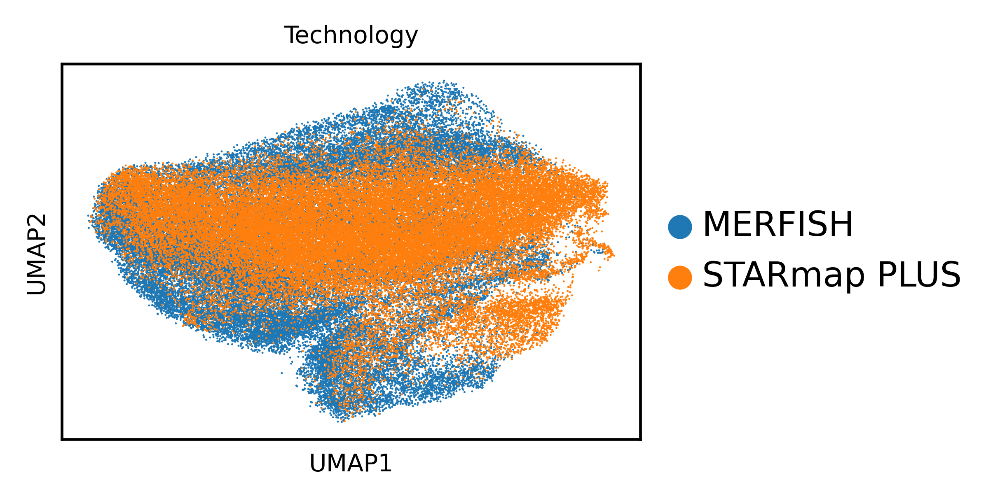

/tmp/ipykernel_4056945/3447051690.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"


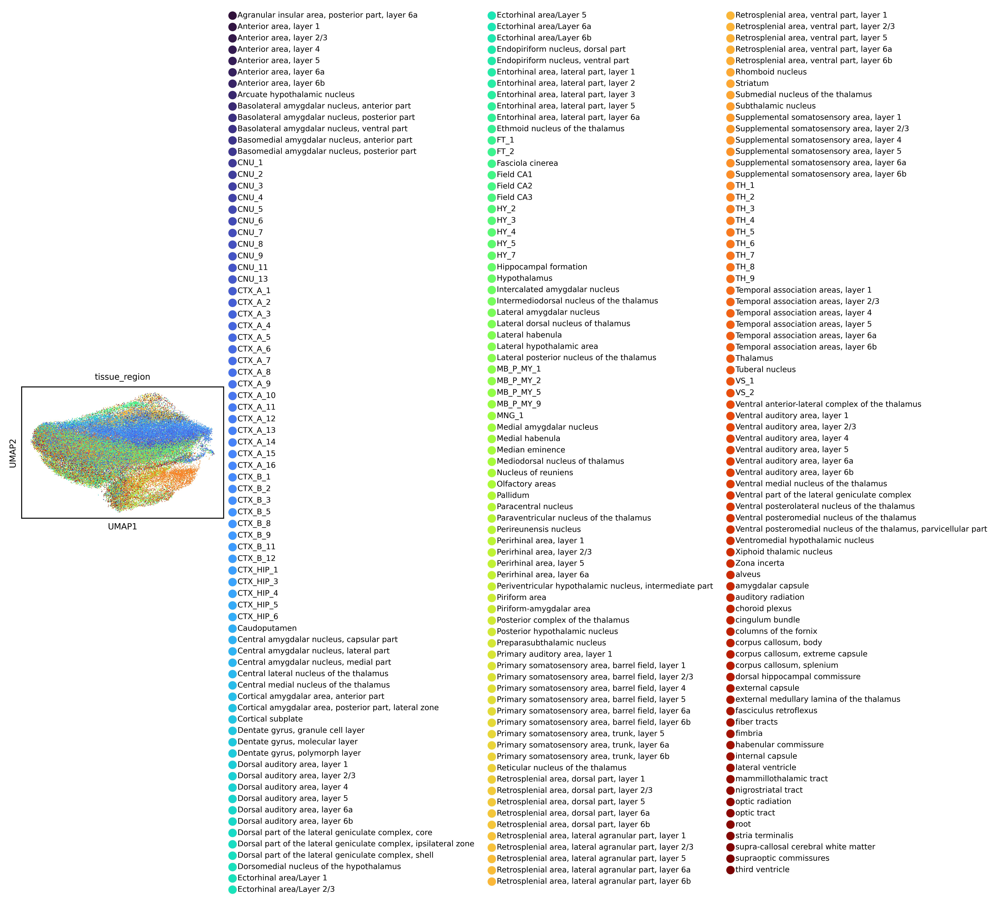

In [31]:
sc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                n_pcs=n_pcs, key_added=emb_key)
sc.tl.umap(adata, neighbors_key=emb_key)

n_pcs_string = f"_{n_pcs}_pcs" if n_pcs else ""
categories = adata.obs[batch_key].cat.categories.tolist()
assert len(categories) == 2, "Expected exactly 2 categories for batch_key"
rename = dict(zip(sorted(categories), ["MERFISH", "STARmap PLUS"]))
adata.obs[batch_key] = adata.obs[batch_key].map(rename).astype("category")

sc.pl.umap(
    adata,
    color=batch_key,
    title="Technology",
    legend_loc="right margin",
    legend_fontsize=10,
    show=False,
)
for collection in plt.gca().collections:
    collection.set_rasterized(True)
plt.savefig(
    f"{benchmarking_artifacts_folder_path}/nicheformer/{dataset_name}_{emb_key}_umap_by_{batch_key}{n_pcs_string}.svg",
    format="svg", bbox_inches="tight"
)
plt.show()
plt.close()

for label_key in label_keys:
    n_cats = adata.obs[label_key].nunique()
    palette = make_large_cmap(n_cats)
    sc.pl.umap(adata, color=label_key, palette=palette, show=False)
    for collection in plt.gca().collections:
        collection.set_rasterized(True)
    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_umap_by_{label_key}{n_pcs_string}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

In [32]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

### 2.3 Visualize Niches

In [50]:
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

In [51]:
### Plot embedding-based clusters
latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"

sc.tl.leiden(adata,
             neighbors_key=emb_key,
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution,
             flavor="igraph",
             n_iterations=2)

In [52]:
print(adata.obs[latent_cluster_key].nunique())
print(adata.obs[latent_cluster_key].value_counts())

30
1     7034
25    7018
17    6248
11    6049
22    5299
3     4878
8     4365
0     4296
16    3834
18    3308
13    3191
4     3082
14    2971
2     2586
19    2541
15    2195
12    2187
20    2153
7     2104
24    2037
10    1931
9     1518
5     1294
6     1080
28     838
21     807
23     407
29     176
26     153
27     124
Name: X_niche_embeddings_clusters_res_1.55, dtype: int64


In [53]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded_clustered.h5ad')

/tmp/ipykernel_4056945/93824751.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/nicheformer/lib/python3.10/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


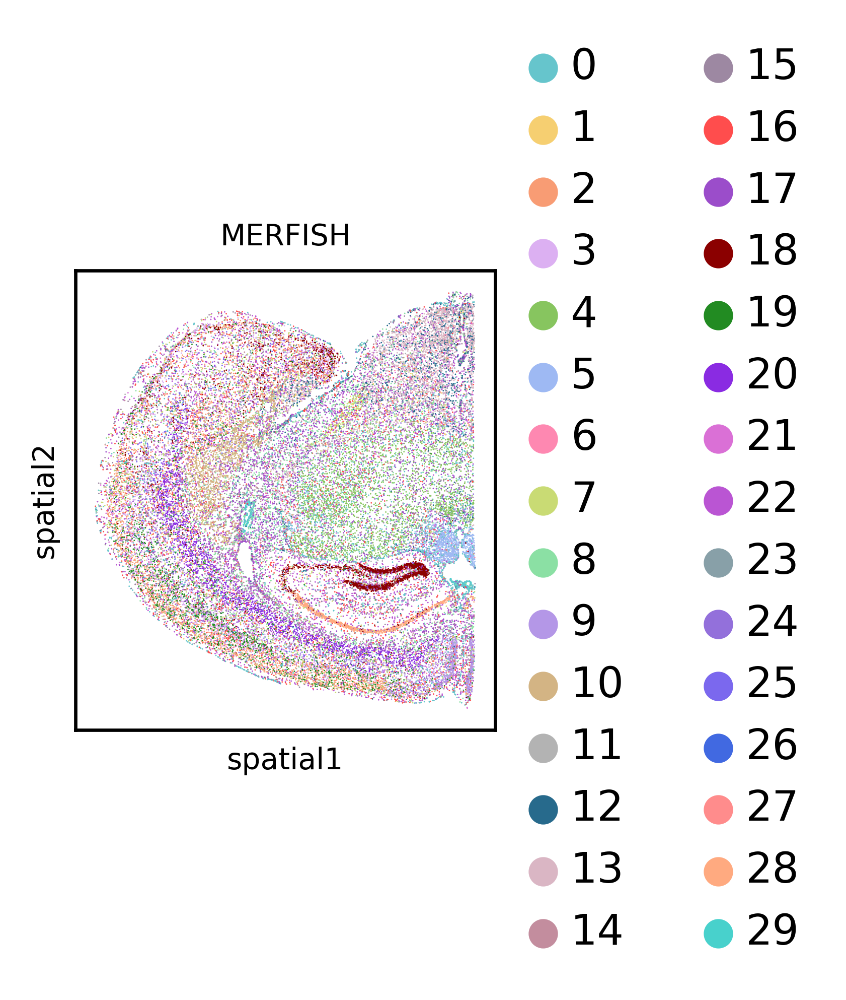

/tmp/ipykernel_4056945/93824751.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/nicheformer/lib/python3.10/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


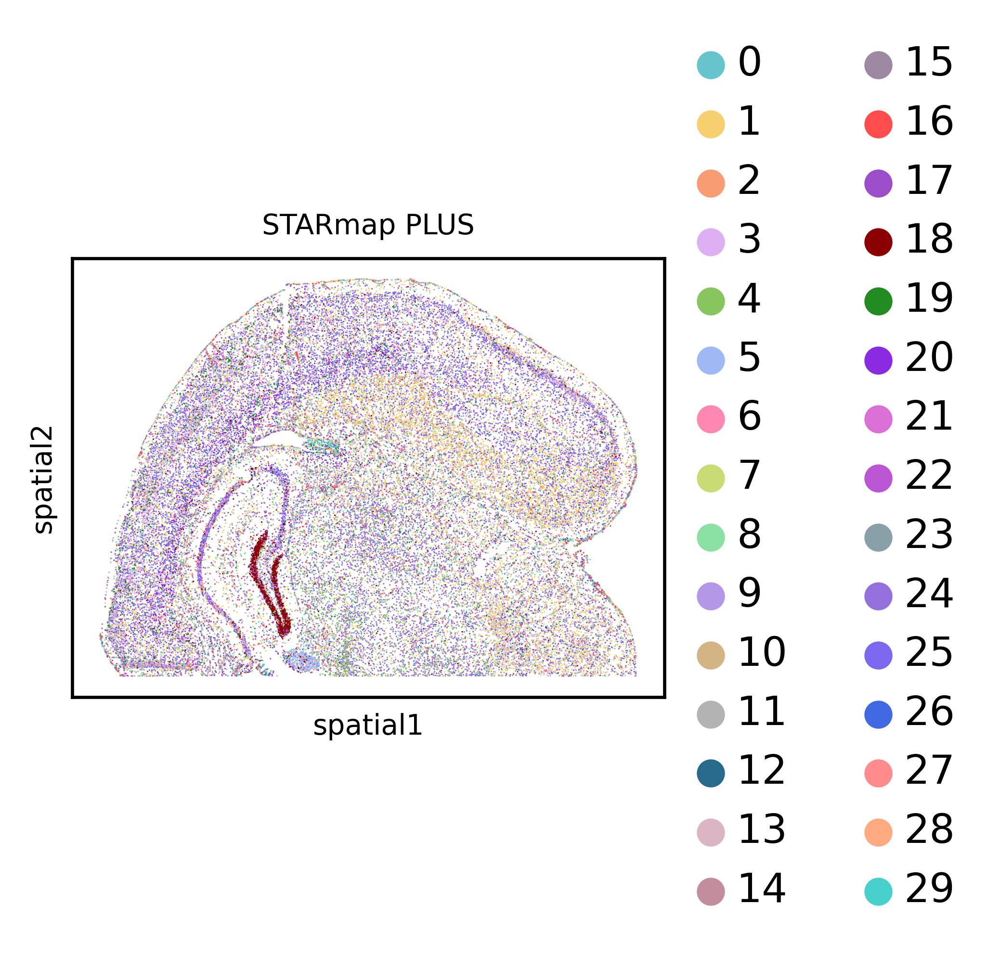

In [54]:
samples = adata.obs[batch_key].unique().tolist()
for sample in samples:
    adata_sample = adata[adata.obs[batch_key] == sample]
    sc.pl.spatial(
        adata_sample,
        color=latent_cluster_key,
        palette=custom_palette,
        spot_size=spot_sizes[sample],
        title=sample,
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )

    fig = plt.gcf()
    for ax in fig.axes:
        for child in ax.get_children():
            if isinstance(child, mpl.image.AxesImage):
                child.set_rasterized(True)
        for collection in ax.collections:
            collection.set_rasterized(True)

    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/tissue_{sample}_by_{latent_cluster_key}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

### 2.4 Compute Metrics

In [55]:
# Compute average cosine similarity of embeddings
X = adata.obsm[emb_key]
X = X / np.linalg.norm(X, axis=1, keepdims=True)
n = X.shape[0]
S = X.sum(axis=0)
avg_cos_sim = (S @ S - n) / (n * (n - 1))
print(f'{emb_key} average cosine similarity: {avg_cos_sim}')

cos_sim_result = pd.DataFrame([{
    "emb_key": emb_key,
    "avg_cosine_similarity": avg_cos_sim,
}])

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/"
    f"{dataset_name}_{emb_key}_avg_cosine_similarity.csv"
)
cos_sim_result.to_csv(out_path, index=False)
print(f"Saved → {out_path}")

X_niche_embeddings average cosine similarity: 0.9646324819556545
Saved → /nfs/team361/sb75/stjepa-reproducibility/artifacts/benchmarking/nicheformer/mmb0-1b_smb1-1b_1p_X_niche_embeddings_avg_cosine_similarity.csv


In [56]:
# Compute NMI and ARI with region annotations
results = []
for region_key in ["Sub_molecular_tissue_region", "ccf_region_name"]:
    mask = adata.obs[region_key].notna()
    labels_true = adata.obs.loc[mask, region_key]
    labels_pred = adata.obs.loc[mask, latent_cluster_key]
    nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
    ari = skm.adjusted_rand_score(labels_true, labels_pred)
    print(f"NMI ({region_key}): {nmi:.4f}")
    print(f"ARI ({region_key}): {ari:.4f}")
    results.append({"region_key": region_key, "NMI": nmi, "ARI": ari})

df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{latent_cluster_key}_niche_identification_metrics.csv",
    index=False
)

NMI (Sub_molecular_tissue_region): 0.1724
ARI (Sub_molecular_tissue_region): 0.0456
NMI (ccf_region_name): 0.2395
ARI (ccf_region_name): 0.0704


In [57]:
# Compute batch integration metrics
results = []

# iLISI
batch = adata.obs[batch_key].values
knn = pynndescent(adata.obsm[emb_key], n_neighbors=90)
ilisi = float(np.mean(ilisi_knn(knn, batch)))
print(f"iLISI: {ilisi:.4f}")
results.append({"metric": "iLISI", "score": ilisi})

# ASW
asw = silhouette_score(
    adata.obsm[emb_key],
    adata.obs["batch"],
    metric="euclidean",
    sample_size=10000
)
print(f"ASW batch: {asw:.4f}")
results.append({"metric": "ASW", "score": asw})

# MMD
mmd_score = mmd_comparable(adata, emb_key, batch_key)
print(f"MMD: {mmd_score:.4f}")
results.append({"metric": "MMD", "score": mmd_score})

# Save
df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_batch_integration_metrics.csv",
    index=False
)

INFO:2026-04-07 12:34:00,791:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


iLISI: 0.1587
ASW batch: 0.0326
MMD: 0.0369


In [58]:
# --- Config -----------------------------------------------------------
latent_leiden_resolution = 1.0
N_STEPS   = 4      # points above and below base resolution
STEP_SIZE = 0.1
MIN_RES   = 0.1    # Leiden resolution must be > 0

region_keys = ["Sub_molecular_tissue_region", "ccf_region_name"]

# Build resolution grid: N_STEPS below and above base, clamped to MIN_RES
# Use integer steps to avoid float accumulation errors in np.arange
base_int = round(latent_leiden_resolution / STEP_SIZE)  # e.g. 1.0/0.1 -> 10
resolutions = [
    round(step * STEP_SIZE, 1)
    for step in range(base_int - N_STEPS, base_int + N_STEPS + 1)
    if step * STEP_SIZE >= MIN_RES
]

# --- Sweep ------------------------------------------------------------
all_results = []

for res in resolutions:
    cluster_key = f"{emb_key}_clusters_res_{res}"

    # Leiden clustering
    try:
        rsc.tl.leiden(adata,
                      neighbors_key=emb_key,
                      key_added=cluster_key,
                      resolution=res,
                      flavor="igraph",
                      n_iterations=2)
    except NameError:
        sc.tl.leiden(adata,
                     neighbors_key=emb_key,
                     key_added=cluster_key,
                     resolution=res,
                     flavor="igraph",
                     n_iterations=2)

    n_clusters = adata.obs[cluster_key].nunique()
    print(f"\n── Resolution {res:.1f}  ({n_clusters} clusters) ──")

    for region_key in region_keys:
        mask        = adata.obs[region_key].notna()
        labels_true = adata.obs.loc[mask, region_key]
        labels_pred = adata.obs.loc[mask, cluster_key]

        nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
        ari = skm.adjusted_rand_score(labels_true, labels_pred)
        print(f"  {region_key:40s}  NMI={nmi:.4f}  ARI={ari:.4f}")

        all_results.append({
            "resolution": res,
            "n_clusters": n_clusters,
            "region_key": region_key,
            "NMI":        nmi,
            "ARI":        ari,
        })

# --- Save -------------------------------------------------------------
df = pd.DataFrame(all_results)

# Canonical column order
df = df[["resolution", "n_clusters", "region_key", "NMI", "ARI"]]

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/"
    f"{dataset_name}_{emb_key}_niche_identification_metrics_res_sweep.csv"
)
df.to_csv(out_path, index=False)
print(f"\nSaved {len(df)} rows → {out_path}")


── Resolution 0.6  (15 clusters) ──
  Sub_molecular_tissue_region               NMI=0.1394  ARI=0.0386
  ccf_region_name                           NMI=0.1783  ARI=0.0258

── Resolution 0.7  (19 clusters) ──
  Sub_molecular_tissue_region               NMI=0.1539  ARI=0.0414
  ccf_region_name                           NMI=0.2045  ARI=0.0328

── Resolution 0.8  (19 clusters) ──
  Sub_molecular_tissue_region               NMI=0.1509  ARI=0.0431
  ccf_region_name                           NMI=0.2110  ARI=0.0400

── Resolution 0.9  (23 clusters) ──
  Sub_molecular_tissue_region               NMI=0.1524  ARI=0.0454
  ccf_region_name                           NMI=0.2174  ARI=0.0435

── Resolution 1.0  (25 clusters) ──
  Sub_molecular_tissue_region               NMI=0.1643  ARI=0.0479
  ccf_region_name                           NMI=0.2302  ARI=0.0489

── Resolution 1.1  (25 clusters) ──
  Sub_molecular_tissue_region               NMI=0.1598  ARI=0.0468
  ccf_region_name                        